# Klasifikasi Audio: SAWMIL vs NON SAWMIL
## Implementasi Strategi Optimasi Berdasarkan Rekomendasi Algoritma

Notebook ini mengimplementasikan rekomendasi dari dokumen **`Strategi Optimasi.md`** untuk melakukan klasifikasi audio biner (SAWMIL dan NON SAWMIL) berdasarkan fitur ekstraksi Librosa (MFCC, Chroma, Spectral Centroid, Spectral Bandwidth, Spectral Rolloff, ZCR, dan RMS).

### Algoritma yang Diuji:
1. **SVM-RBF** (*Kandidat Model Utama*) + Pipeline StandardScaler
2. **Random Forest Classifier** (*Baseline Ensemble Learning*)
3. **XGBoost Classifier** (*Kandidat Model Utama Gradient Boosting*)
4. **LightGBM Classifier** (*Model Pembanding Boosting*)

### Strategi Optimasi:
- **Pencegahan Data Leakage**: Pemisahan awal *Holdout Test Set* (20%) dan Feature Scaling berada di dalam Pipeline.
- **Stratified 5-Fold Cross-Validation**: Menjaga proporsi kelas di setiap fold.
- **Hyperparameter Tuning**: Pencarian parameter optimal menggunakan `GridSearchCV` / `RandomizedSearchCV`.
- **Cell Terpisah**: Setiap proses pelatihan & tuning yang memakan waktu ditempatkan pada **cell terpisah** agar dapat dieksekusi secara mandiri.

### 1. Import Library dan Konfigurasi Lingkungan

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Model & Preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve, auc
)

# Gradient Boosting Libraries
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import joblib

# Konfigurasi tampilan
sns.set_theme(style='whitegrid')
warnings.filterwarnings('ignore')

### 2. Memuat dan Memeriksa Dataset Hasil Ekstraksi Audio

In [2]:
# Membaca dataset CSV hasil ekstraksi fitur Librosa
csv_path = 'hasil_ekstraksi_audio.csv'
df = pd.read_csv(csv_path)

print(f"Bentuk dataset (baris, kolom): {df.shape}")
print("\nDistribusi Label Target:")
print(df['label'].value_counts())

# Menampilkan 5 baris pertama
df.head()

Bentuk dataset (baris, kolom): (200, 76)

Distribusi Label Target:
label
SAWMIL        100
NON SAWMIL    100
Name: count, dtype: int64


,filename,label,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,...,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,zcr_mean,zcr_std,rms_mean,rms_std
0,1.mp3,SAWMIL,-154.092499,23.846697,92.204659,13.963578,49.628963,8.349650,47.014332,6.460558,...,1975.898071,398.667158,2740.698550,279.290362,5164.828491,1027.055430,0.077980,0.018720,0.105194,0.014928
1,10.mp3,SAWMIL,-90.875938,24.508070,58.004902,16.022915,-15.412866,8.375935,-11.365315,7.831729,...,3385.732029,433.215749,3079.102760,80.019106,7855.681356,355.678366,0.153641,0.056451,0.092373,0.020678
2,100.mp3,SAWMIL,-88.144463,30.498030,96.341797,36.586918,-8.203456,14.114124,10.363613,16.264250,...,2198.079427,617.058055,2417.036452,343.385056,4649.427287,1346.482860,0.102141,0.022456,0.142866,0.030866
3,11.mp3,SAWMIL,-202.864624,52.743198,59.629662,17.923719,3.296696,9.415070,12.391150,11.962558,...,3806.184872,696.705519,3189.021224,228.935572,8098.129272,877.778870,0.224453,0.058238,0.026545,0.016727
4,12.mp3,SAWMIL,-98.233940,46.728466,34.001640,13.481186,-14.537036,13.989621,6.683242,9.979526,...,4029.845803,286.560861,2964.657321,209.937052,7714.220174,580.883033,0.266446,0.035347,0.070882,0.024069


### 3. Persiapan Data (Pencegahan Data Leakage & Pembagian Train-Test)
- Fitur non-numerik seperti `filename` dan `label` dipisahkan.
- Label target di-encode: **SAWMIL = 1**, **NON SAWMIL = 0**.
- Dataset dibagi menjadi **80% Training Data** dan **20% Testing Data** menggunakan `StratifiedSplit`.

In [3]:
# 1. Mapping label target ke biner (SAWMIL = 1, NON SAWMIL = 0)
label_map = {'NON SAWMIL': 0, 'SAWMIL': 1}
df['target'] = df['label'].map(label_map)

# 2. Pisahkan fitur X dan target y
X = df.drop(columns=['filename', 'label', 'target'])
y = df['target']

print(f"Total Fitur Input: {X.shape[1]}")

# 3. Split Train & Test (Pencegahan Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Jumlah Data Latih (Train): {X_train.shape[0]} sampel")
print(f"Jumlah Data Uji (Test): {X_test.shape[0]} sampel")

# 4. Setup Stratified 5-Fold Cross-Validation untuk data latih
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary untuk menyimpan model terbaik & riwayat evaluasi CV
best_models = {}
cv_results_summary = {}

Total Fitur Input: 74
Jumlah Data Latih (Train): 160 sampel
Jumlah Data Uji (Test): 40 sampel


---
## 4. Eksperimen Model Machine Learning & Hyperparameter Tuning

> **Catatan:** Masing-masing algoritma di bawah ini ditempatkan pada **cell terpisah** karena proses *Hyperparameter Tuning* (pencarian kombinasi parameter optimal pada 5-Fold CV) memerlukan waktu komputasi. Anda dapat mengeksekusi cell model satu per satu sesuai kebutuhan.

### 4.1 Eksperimen 1: Support Vector Machine (SVM-RBF)
- **Strategi:** SVM sangat sensitif terhadap skala fitur audio, sehingga `StandardScaler` wajib digunakan.
- **Pencegahan Leakage:** `StandardScaler` dibungkus bersama `SVC` ke dalam **`Pipeline`** sehingga proses scaling hanya difit pada data training fold masing-masing.
- **Parameter yang dioptimasi:** `C` (kekuatan regularisasi) dan `gamma` (radius pengaruh RBF).

In [4]:
# [CELL TERPISAH] HYPERPARAMETER TUNING: SVM-RBF
start_time = time.time()

# Pipeline: Scaling -> SVM
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', probability=True, random_state=42))
])

# Ruang parameter untuk GridSearchCV
param_grid_svm = {
    'svm__C': [0.1, 1, 5, 10, 50, 100],
    'svm__gamma': ['scale', 'auto', 0.001, 0.01, 0.05, 0.1]
}

print("Memulai Tuning SVM-RBF dengan 5-Fold Stratified CV...")
grid_svm = GridSearchCV(
    estimator=pipe_svm,
    param_grid=param_grid_svm,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_svm.fit(X_train, y_train)
elapsed_svm = time.time() - start_time

# Simpan model terbaik
best_models['SVM-RBF'] = grid_svm.best_estimator_
cv_results_summary['SVM-RBF'] = grid_svm.best_score_

print(f"\n[SELESAI] Waktu eksekusi: {elapsed_svm:.2f} detik")
print(f"Best Hyperparameters: {grid_svm.best_params_}")
print(f"Best 5-Fold CV Accuracy: {grid_svm.best_score_ * 100:.2f}%")

Memulai Tuning SVM-RBF dengan 5-Fold Stratified CV...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

[SELESAI] Waktu eksekusi: 9.24 detik
Best Hyperparameters: {'svm__C': 5, 'svm__gamma': 'scale'}
Best 5-Fold CV Accuracy: 97.50%


### 4.2 Eksperimen 2: Random Forest Classifier
- **Strategi:** Ensemble bagging dari banyak decision tree, relatif tahan terhadap data bising.
- **Parameter yang dioptimasi:** `n_estimators`, `max_depth`, `min_samples_split`, dan `min_samples_leaf`.

In [5]:
# [CELL TERPISAH] HYPERPARAMETER TUNING: RANDOM FOREST
start_time = time.time()

rf = RandomForestClassifier(random_state=42)

# Ruang parameter untuk GridSearchCV
param_grid_rf = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

print("Memulai Tuning Random Forest dengan 5-Fold Stratified CV...")
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)
elapsed_rf = time.time() - start_time

# Simpan model terbaik
best_models['Random Forest'] = grid_rf.best_estimator_
cv_results_summary['Random Forest'] = grid_rf.best_score_

print(f"\n[SELESAI] Waktu eksekusi: {elapsed_rf:.2f} detik")
print(f"Best Hyperparameters: {grid_rf.best_params_}")
print(f"Best 5-Fold CV Accuracy: {grid_rf.best_score_ * 100:.2f}%")

Memulai Tuning Random Forest dengan 5-Fold Stratified CV...
Fitting 5 folds for each of 144 candidates, totalling 720 fits

[SELESAI] Waktu eksekusi: 39.44 detik
Best Hyperparameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}
Best 5-Fold CV Accuracy: 97.50%


### 4.3 Eksperimen 3: XGBoost Classifier (Kandidat Model Utama)
- **Strategi:** Extreme Gradient Boosting dengan regularisasi (L1/L2) untuk mengendalikan overfitting.
- **Parameter yang dioptimasi:** `n_estimators`, `max_depth`, `learning_rate`, `subsample`, dan `colsample_bytree`.

In [6]:
# [CELL TERPISAH] HYPERPARAMETER TUNING: XGBOOST
start_time = time.time()

xgb = XGBClassifier(
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)

# Ruang parameter untuk GridSearchCV
param_grid_xgb = {
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [3, 4, 6],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0]
}

print("Memulai Tuning XGBoost dengan 5-Fold Stratified CV...")
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid_xgb,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_xgb.fit(X_train, y_train)
elapsed_xgb = time.time() - start_time

# Simpan model terbaik
best_models['XGBoost'] = grid_xgb.best_estimator_
cv_results_summary['XGBoost'] = grid_xgb.best_score_

print(f"\n[SELESAI] Waktu eksekusi: {elapsed_xgb:.2f} detik")
print(f"Best Hyperparameters: {grid_xgb.best_params_}")
print(f"Best 5-Fold CV Accuracy: {grid_xgb.best_score_ * 100:.2f}%")

Memulai Tuning XGBoost dengan 5-Fold Stratified CV...
Fitting 5 folds for each of 432 candidates, totalling 2160 fits

[SELESAI] Waktu eksekusi: 47.61 detik
Best Hyperparameters: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 150, 'subsample': 0.7}
Best 5-Fold CV Accuracy: 95.00%


### 4.4 Eksperimen 4: LightGBM Classifier (Model Pembanding)
- **Strategi:** Gradient Boosting berbasis Leaf-wise tree, sangat efisien dan cepat dalam pelatihan data berfitur banyak.
- **Parameter yang dioptimasi:** `n_estimators`, `max_depth`, `learning_rate`, dan `num_leaves`.

In [7]:
# [CELL TERPISAH] HYPERPARAMETER TUNING: LIGHTGBM
start_time = time.time()

lgbm = LGBMClassifier(random_state=42, verbose=-1)

# Ruang parameter untuk GridSearchCV
param_grid_lgbm = {
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [-1, 3, 5, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'num_leaves': [15, 31, 63]
}

print("Memulai Tuning LightGBM dengan 5-Fold Stratified CV...")
grid_lgbm = GridSearchCV(
    estimator=lgbm,
    param_grid=param_grid_lgbm,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_lgbm.fit(X_train, y_train)
elapsed_lgbm = time.time() - start_time

# Simpan model terbaik
best_models['LightGBM'] = grid_lgbm.best_estimator_
cv_results_summary['LightGBM'] = grid_lgbm.best_score_

print(f"\n[SELESAI] Waktu eksekusi: {elapsed_lgbm:.2f} detik")
print(f"Best Hyperparameters: {grid_lgbm.best_params_}")
print(f"Best 5-Fold CV Accuracy: {grid_lgbm.best_score_ * 100:.2f}%")

Memulai Tuning LightGBM dengan 5-Fold Stratified CV...
Fitting 5 folds for each of 192 candidates, totalling 960 fits



[SELESAI] Waktu eksekusi: 62.62 detik
Best Hyperparameters: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 150, 'num_leaves': 15}
Best 5-Fold CV Accuracy: 96.25%


---
## 5. Perbandingan Performa Validasi Silang (Cross-Validation)

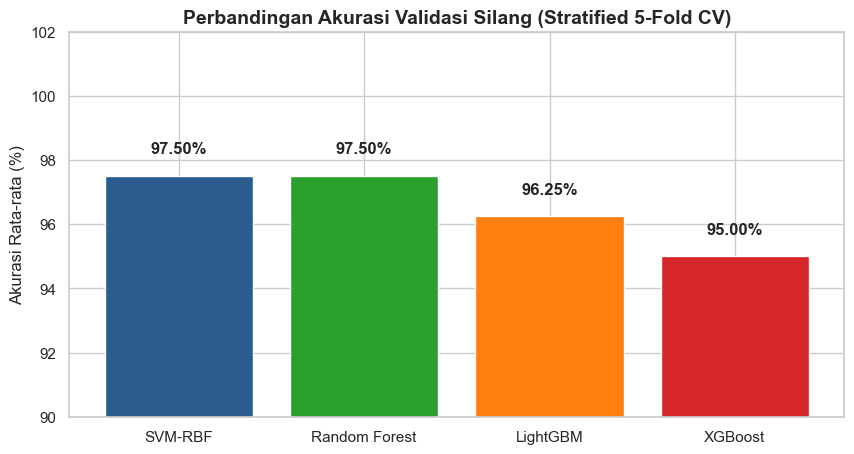

,Algoritma,Akurasi CV 5-Fold,Akurasi CV (%)
0,SVM-RBF,0.9750,97.50
1,Random Forest,0.9750,97.50
2,LightGBM,0.9625,96.25
3,XGBoost,0.9500,95.00


In [8]:
# Membuat tabel perbandingan skor CV
cv_df = pd.DataFrame(list(cv_results_summary.items()), columns=['Algoritma', 'Akurasi CV 5-Fold'])
cv_df['Akurasi CV (%)'] = cv_df['Akurasi CV 5-Fold'] * 100
cv_df = cv_df.sort_values(by='Akurasi CV 5-Fold', ascending=False).reset_index(drop=True)

# Visualisasi Perbandingan
plt.figure(figsize=(10, 5))
bars = plt.bar(cv_df['Algoritma'], cv_df['Akurasi CV (%)'], color=['#2b5c8f', '#2ca02c', '#ff7f0e', '#d62728'])
plt.ylim(min(cv_df['Akurasi CV (%)']) - 5, 102)
plt.title('Perbandingan Akurasi Validasi Silang (Stratified 5-Fold CV)', fontsize=14, fontweight='bold')
plt.ylabel('Akurasi Rata-rata (%)', fontsize=12)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.6, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.show()
display(cv_df)

---
## 6. Evaluasi Model Terbaik pada Data Testing (Holdout Set)

> Data pengujian (**20% Holdout Test**) belum pernah dilihat oleh model saat proses pelatihan maupun hyperparameter tuning. Tahap ini membuktikan kemampuan generalisasi model terhadap audio baru.

In [17]:
# Menentukan model terbaik berdasarkan skor CV tertinggi
best_algo_name = cv_df.iloc[0]['Algoritma']
best_estimator = best_models[best_algo_name]

print(f"--- MODEL TERBAIK TERPILIH: {best_algo_name} ---\n")

# Prediksi pada data testing
y_pred = best_estimator.predict(X_test)
y_proba = best_estimator.predict_proba(X_test)[:, 1]

# Perhitungan metrik evaluasi
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Metrik Evaluasi Data Testing:")
print(f"- Accuracy  : {acc * 100:.2f}%")
print(f"- Precision : {prec * 100:.2f}%")
print(f"- Recall    : {rec * 100:.2f}%")
print(f"- F1-Score  : {f1 * 100:.2f}%")
print(f"- ROC-AUC   : {roc_auc:.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['NON SAWMIL', 'SAWMIL']))

--- MODEL TERBAIK TERPILIH: SVM-RBF ---

Metrik Evaluasi Data Testing:
- Accuracy  : 100.00%
- Precision : 100.00%
- Recall    : 100.00%
- F1-Score  : 100.00%
- ROC-AUC   : 1.0000

--- Classification Report ---
              precision    recall  f1-score   support

  NON SAWMIL       1.00      1.00      1.00        20
      SAWMIL       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



### 7. Visualisasi Confusion Matrix & Kurva ROC (Data Testing)

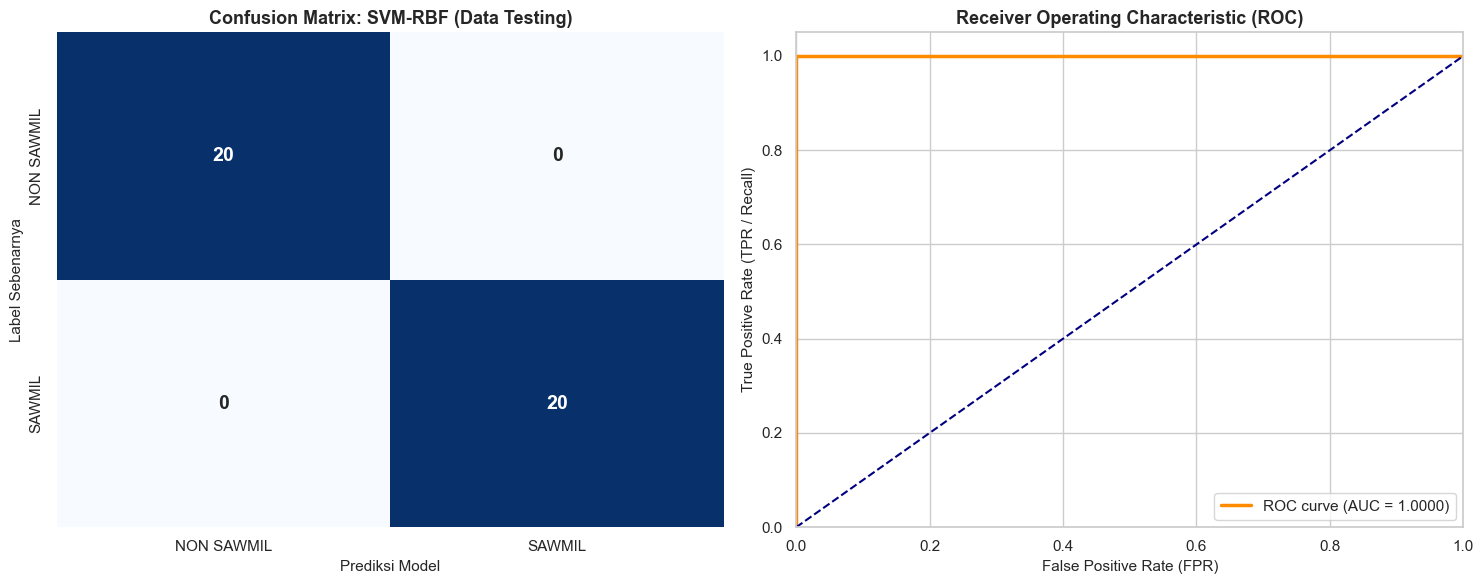

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
    xticklabels=['NON SAWMIL', 'SAWMIL'],
    yticklabels=['NON SAWMIL', 'SAWMIL'],
    cbar=False,
    annot_kws={'size': 14, 'weight': 'bold'}
)
ax1.set_title(f'Confusion Matrix: {best_algo_name} (Data Testing)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Prediksi Model', fontsize=11)
ax1.set_ylabel('Label Sebenarnya', fontsize=11)

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
ax2.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ROC curve (AUC = {roc_auc:.4f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate (FPR)', fontsize=11)
ax2.set_ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
ax2.set_title('Receiver Operating Characteristic (ROC)', fontsize=13, fontweight='bold')
ax2.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

### 8. Analisis Fitur Terpenting (Feature Importance)
Menganalisis fitur-fitur audio apa yang memiliki kontribusi paling tinggi dalam membedakan suara **SAWMIL** (mesin gergaji kayu) dari suara **NON SAWMIL**.

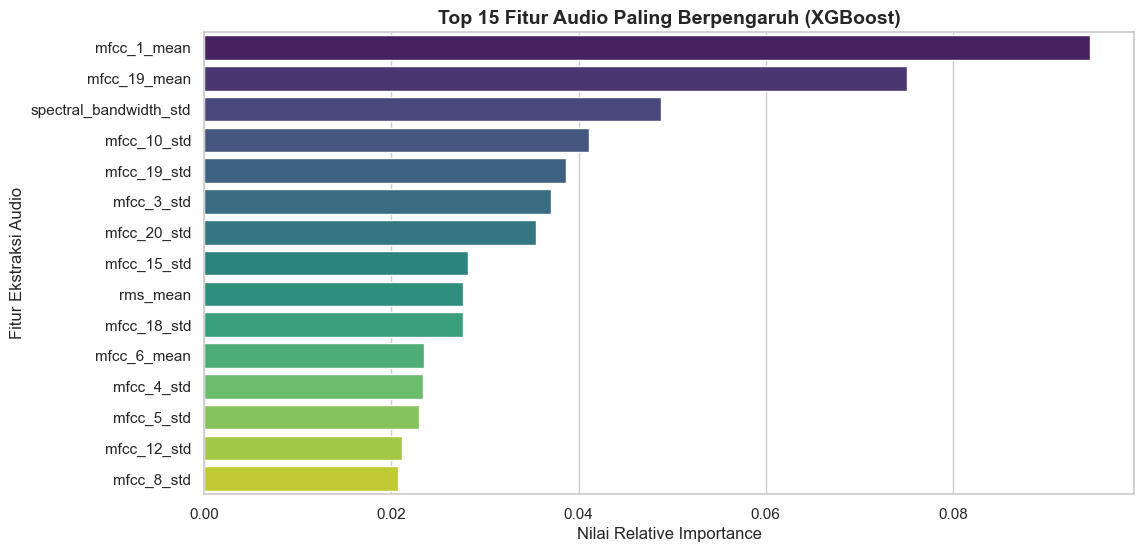

,Fitur,Importance
0,mfcc_1_mean,0.094657
36,mfcc_19_mean,0.075071
67,spectral_bandwidth_std,0.048811
19,mfcc_10_std,0.041168
37,mfcc_19_std,0.038697
5,mfcc_3_std,0.037079
39,mfcc_20_std,0.035424
29,mfcc_15_std,0.028184
72,rms_mean,0.027701
35,mfcc_18_std,0.027604


In [18]:
# Ekstraksi Feature Importance dari model tree (XGBoost, LightGBM, atau Random Forest)
if hasattr(best_estimator, 'feature_importances_'):
    model_for_fi = best_estimator
    model_name_fi = best_algo_name
elif 'XGBoost' in best_models:
    model_for_fi = best_models['XGBoost']
    model_name_fi = 'XGBoost'
else:
    model_for_fi = best_models['Random Forest']
    model_name_fi = 'Random Forest'

importances = model_for_fi.feature_importances_
feature_names = X.columns

# Buat DataFrame Top 15 Fitur Terpenting
fi_df = pd.DataFrame({
    'Fitur': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Fitur', data=fi_df, palette='viridis')
plt.title(f'Top 15 Fitur Audio Paling Berpengaruh ({model_name_fi})', fontsize=14, fontweight='bold')
plt.xlabel('Nilai Relative Importance', fontsize=12)
plt.ylabel('Fitur Ekstraksi Audio', fontsize=12)
plt.show()

display(fi_df)

### 9. Menyimpan Model Terbaik untuk Deployment

In [19]:
# Simpan model terbaik terpilih ke file .joblib
model_output_filename = 'model_terbaik_klasifikasi_audio.joblib'
joblib.dump(best_estimator, model_output_filename)

print(f"Model terbaik ({best_algo_name}) berhasil disimpan sebagai: '{model_output_filename}'")
print("Model ini siap digunakan untuk inferensi atau pembuatan aplikasi Web Audio Klasifikasi.")

Model terbaik (SVM-RBF) berhasil disimpan sebagai: 'model_terbaik_klasifikasi_audio.joblib'
Model ini siap digunakan untuk inferensi atau pembuatan aplikasi Web Audio Klasifikasi.
